In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import csv
from tqdm import tqdm
import chemparse
import json
import math
import os

In [17]:
# Matplotlib defaults

font = {"family" : "normal",
    "size" : 22}

for key, value in font.items():
    plt.rcParams.update({"font." + key : value})

## Predicting chiral changes via heavy atom count

Using Laurent et al's model

In [3]:
#Read in chirality of all KEGG compounds
fp = "Data/chiral_molweight_formula_labels.csv"
df = pd.read_csv(fp)
df.head()

,C,S,Chiral_Centers,Mol_Weight,Formula
0,C00001,NaN,0,18.0153,H2O
1,C00002,Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O...,4,507.1810,C10H16N5O13P3
2,C00003,NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)...,8,664.4330,C21H28N7O14P2
3,C00004,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,8,665.4410,C21H29N7O14P2
4,C00005,NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...,8,745.4209,C21H30N7O17P3


In [4]:
def getFormulaDict(f):
    
    return chemparse.parse_formula(f)

In [5]:
def getNumHeavyAtoms(f):
    """ Find the number of heavy atoms (non-Hs)

    Args:
        f (dict): dictionary of elements & atom counts

    Returns:
        int: number of non-H atoms
    """
    #Remove Hs
    if "H" in f:
        f.pop("H")

    #Count number of other atoms (heavy atoms are non-Hs)
    return sum(f.values())

In [6]:
tqdm.pandas()
df["formula_dict"] = df["Formula"].progress_apply(getFormulaDict)
df["Heavy_Atoms"] = df["formula_dict"].progress_apply(getNumHeavyAtoms)

 12%|█▏        | 2219/17963 [00:00<00:00, 22181.14it/s]

100%|██████████| 17963/17963 [00:00<00:00, 507225.64it/s]


In [7]:
### Find which formulas appear in domains

def find_domain(formula, domain_cpds):
    if formula in domain_cpds:
        return 1
    else:
        return 0

In [8]:
from glob import glob

for domain in ["archaea", "bacteria", "metagenome", "eukarya"]:
    print("---- Analyzing", domain, "----")
    domain_df = pd.read_csv("Data/" + domain + "_occurance.csv")
    domain_cpds = list(domain_df["Cpd"])

    df[domain] = df["C"].apply(find_domain, args=(domain_cpds,))


---- Analyzing archaea ----
---- Analyzing bacteria ----
---- Analyzing metagenome ----
---- Analyzing eukarya ----


In [9]:
print(df)

            C                                                  S  \
0      C00001                                                NaN   
1      C00002  Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O...   
2      C00003  NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)...   
3      C00004  NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...   
4      C00005  NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...   
...       ...                                                ...   
17958  C22193  CCOc1ccc(Cc2cc([C@@H]3O[C@H](CO)[C@@H](O)[C@H]...   
17959  C22194  OC[C@H]1O[C@@H](c2ccc(Cl)c(Cc3ccc(O[C@H]4CCOC4...   
17960  C22195  NC(=O)c1[nH]nc([C@@H]2O[C@H](CO)[C@@H](O)[C@H]...   
17961  C22196   NC(=O)c1csc([C@@H]2O[C@H](CO)[C@@H](O)[C@H]2O)n1   
17962  C22197                                                NaN   

       Chiral_Centers  Mol_Weight        Formula  \
0                   0     18.0153            H2O   
1                   4    507.1810  C10H16N5O13P3   
2                   8    66

In [10]:
### Get all column sorted out - if a compound is present in bacteria, eukarya, archaea, or metagenome, "all" should be 1
all_column = []

for _, row in df.iterrows():
    found_cpd = 0
    for domain in ["archaea", "bacteria", "metagenome", "eukarya"]:
        if row[domain] == 1 and found_cpd == 0:
            all_column.append(1)
            found_cpd = 1
    if found_cpd == 0:
        all_column.append(0)

df["all"] = all_column
print(df)

            C                                                  S  \
0      C00001                                                NaN   
1      C00002  Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O...   
2      C00003  NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)...   
3      C00004  NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...   
4      C00005  NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)O...   
...       ...                                                ...   
17958  C22193  CCOc1ccc(Cc2cc([C@@H]3O[C@H](CO)[C@@H](O)[C@H]...   
17959  C22194  OC[C@H]1O[C@@H](c2ccc(Cl)c(Cc3ccc(O[C@H]4CCOC4...   
17960  C22195  NC(=O)c1[nH]nc([C@@H]2O[C@H](CO)[C@@H](O)[C@H]...   
17961  C22196   NC(=O)c1csc([C@@H]2O[C@H](CO)[C@@H](O)[C@H]2O)n1   
17962  C22197                                                NaN   

       Chiral_Centers  Mol_Weight        Formula  \
0                   0     18.0153            H2O   
1                   4    507.1810  C10H16N5O13P3   
2                   8    66

In [11]:
### Goal - chiral/achiral fraction at each heavy atom value
def get_chiral_fraction(df, domain):
    chiral_fraction = []
    # chiral_fraction = []

    for i in range(1, int(max(df["Heavy_Atoms"]))):
        sub_df = df[df["Heavy_Atoms"] == i]
        #Filter by domain, if domain exists
        if domain:
            sub_df = sub_df[sub_df[domain] == 1]
        else:
            pass

        if len(sub_df) >= 10:
            chiral_fraction.append(sub_df["Chiral_Centers"].astype(bool).sum(axis=0) / float(len(sub_df)))
        else:
            chiral_fraction.append(float("NaN"))

    achiral_fraction = []

    for cf in chiral_fraction:
        if not math.isnan(cf):
            achiral_fraction.append(1 - cf)
        else:
            achiral_fraction.append(float("NaN"))

    # print(chiral_fraction)
    # print(achiral_fraction)

    return chiral_fraction, achiral_fraction

In [12]:
# print("---- All KEGG ----")
# chiral_fraction, achiral_fraction = get_chiral_fraction(df, None)

print("---- Metagenomes ---")
mg_chiral_fraction, mg_achiral_fraction = get_chiral_fraction(df, "metagenome")

print("---- Bacteria ---")
b_chiral_fraction, b_achiral_fraction = get_chiral_fraction(df, "bacteria")

print("---- Archaea ---")
a_chiral_fraction, a_achiral_fraction = get_chiral_fraction(df, "archaea")

print("---- Eukarya ---")
e_chiral_fraction, e_achiral_fraction = get_chiral_fraction(df, "eukarya")

print("---- Metagenomes, Bacteria, Archaea, and Eukarya ----")
all_chiral_fraction, all_achiral_fraction = get_chiral_fraction(df, "all")


---- Metagenomes ---
---- Bacteria ---
---- Archaea ---
---- Eukarya ---
---- Metagenomes, Bacteria, Archaea, and Eukarya ----


In [13]:
achiral_color = "#FFC012"
chiral_color = "#34CCFF"

In [14]:
plt.figure(figsize=(8,8))

plt.plot(achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
plt.plot(chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Laurent Crossover")

plt.title("All KEGG Cpds")
plt.legend(prop={"size":14})

plt.xlim(0,50)
plt.xlabel("Heavy Atoms")
plt.ylabel("Percent Achiral/Chiral")

NameError: name 'achiral_fraction' is not defined

<Figure size 576x576 with 0 Axes>

Text(0, 0.5, 'Percent Achiral/Chiral')

findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


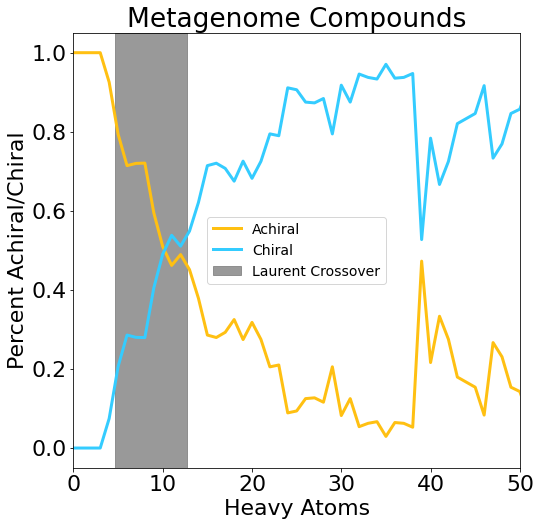

In [ ]:
plt.figure(figsize=(8,8))

plt.plot(mg_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
plt.plot(mg_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Laurent Crossover")

plt.title("Metagenome Compounds")
plt.legend(prop={"size":14})

plt.xlim(0,50)
plt.xlabel("Heavy Atoms")
plt.ylabel("Percent Achiral/Chiral")

Text(0, 0.5, 'Percent Achiral/Chiral')

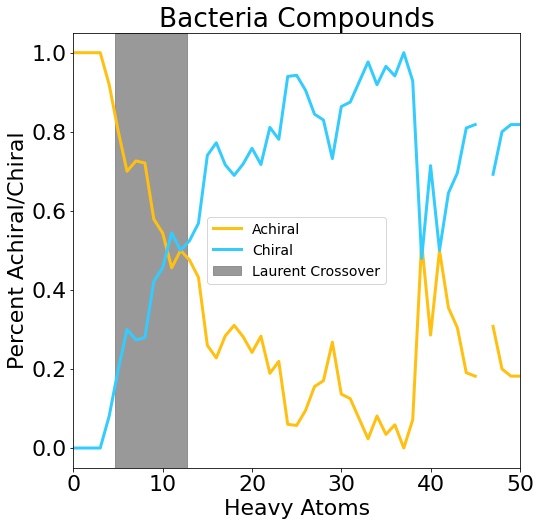

In [ ]:
plt.figure(figsize=(8,8))

plt.plot(b_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
plt.plot(b_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Laurent Crossover")

plt.title("Bacteria Compounds")
plt.legend(prop={"size":14})

plt.xlim(0,50)
plt.xlabel("Heavy Atoms")
plt.ylabel("Percent Achiral/Chiral")

Text(0, 0.5, 'Percent Achiral/Chiral')

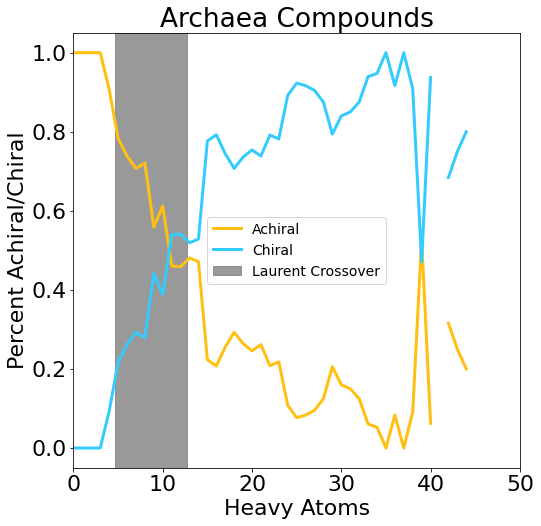

In [ ]:
plt.figure(figsize=(8,8))

plt.plot(a_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
plt.plot(a_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Laurent Crossover")

plt.title("Archaea Compounds")
plt.legend(prop={"size":14})

plt.xlim(0,50)
plt.xlabel("Heavy Atoms")
plt.ylabel("Percent Achiral/Chiral")

Text(0, 0.5, 'Percent Achiral/Chiral')

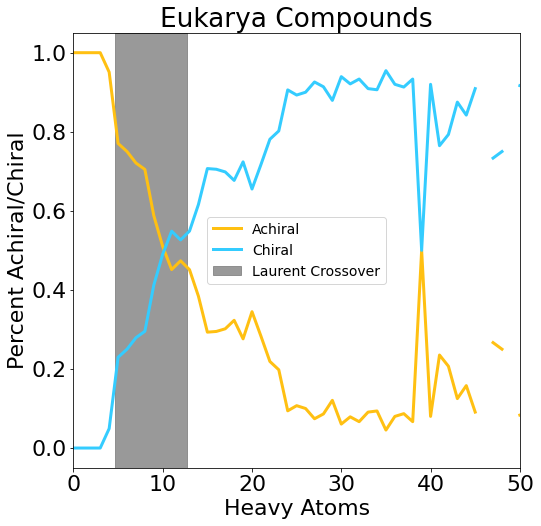

In [ ]:
plt.figure(figsize=(8,8))

plt.plot(e_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
plt.plot(e_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(4.7, 12.7, alpha=0.8, color='grey', label="Laurent Crossover")

plt.title("Eukarya Compounds")
plt.legend(prop={"size":14})

plt.xlim(0,50)
plt.xlabel("Heavy Atoms")
plt.ylabel("Percent Achiral/Chiral")

Text(0.5, 1.0, 'JGI')

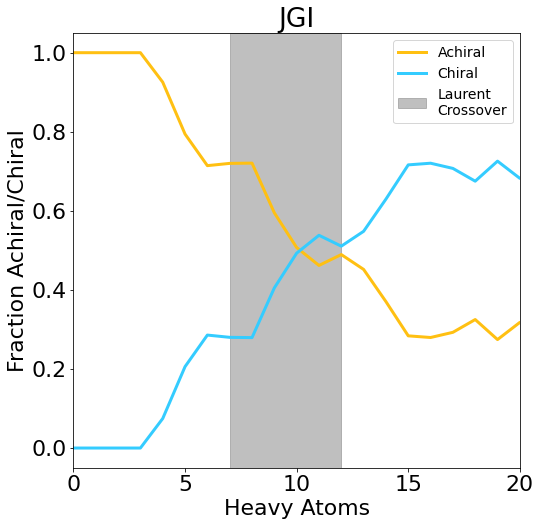

In [ ]:
plt.figure(figsize=(8,8))

plt.plot(all_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
plt.plot(all_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(7, 12, alpha=0.5, color='grey', label="Laurent\nCrossover")

plt.legend(prop={"size":14})

plt.xlim(0,20)
plt.ylim(-0.05, 1.05)
plt.xlabel("Heavy Atoms")
plt.ylabel("Fraction Achiral/Chiral")
plt.title("JGI")

### GDB plotting

In [15]:
gdb_df = pd.read_csv("Data/GDB_output.csv")

print(gdb_df)

    Unnamed: 0  nA  fraction_achiral  fraction_chiral
0            0   1          1.000000         0.000000
1            1   2          1.000000         0.000000
2            2   3          1.000000         0.000000
3            3   4          0.973856         0.026144
4            4   5          0.950704         0.049296
5            5   6          0.832454         0.167546
6            6   7          0.718447         0.281553
7            7   8          0.609405         0.390595
8            8   9          0.466667         0.533333
9            9  10          0.383390         0.616610
10          10  11          0.282346         0.717654
11          11  12          0.193501         0.806499
12          12  13          0.180333         0.819667
13          13  14          0.140667         0.859333
14          14  15          0.054667         0.945333
15          15  16          0.052167         0.947833
16          16  17          0.035167         0.964833
17          17  18          

Text(0.5, 1.0, 'GDB')

findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


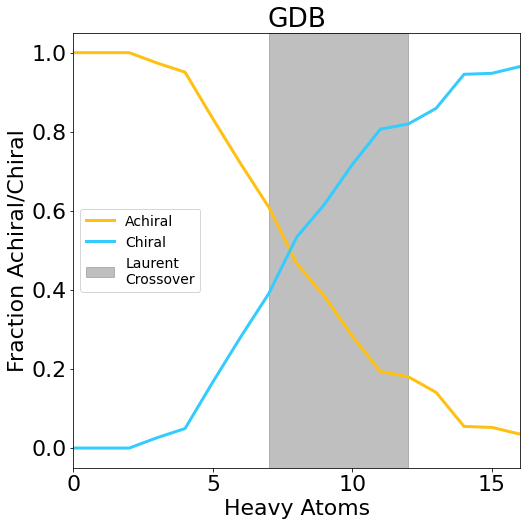

In [18]:
plt.figure(figsize=(8,8))

plt.plot(gdb_df["fraction_achiral"], linewidth=3, label="Achiral", color=achiral_color)
plt.plot(gdb_df["fraction_chiral"], linewidth=3, label="Chiral", color=chiral_color)

plt.axvspan(7, 12, alpha=0.5, color='grey', label="Laurent\nCrossover")

plt.legend(prop={"size":14})

plt.xlim(0,16)
plt.ylim(-0.05, 1.05)
plt.xlabel("Heavy Atoms")
plt.ylabel("Fraction Achiral/Chiral")

plt.title("GDB")


### Chiral order parameter over GDB & KEGG

In [19]:
## GDB counts
gdb_counts_df = pd.read_csv("Data/GDB_raw_counts.csv")
#print(gdb_counts_df)

#Chiral Order Parameter --> cop
gdb_cop = []

for _, row in gdb_counts_df.iterrows():
    gdb_cop.append(row["count_chiral"] / (row["count_achiral"] + row["count_chiral"]))

print(gdb_cop)

[0.0, 0.0, 0.0, 0.026143790849673203, 0.04929577464788732, 0.16754617414248021, 0.2815533980582524, 0.390595009596929, 0.5333333333333333, 0.6166097838452788, 0.7176544240400667, 0.8064989902698734, 0.8196666666666667, 0.8593333333333333, 0.9453333333333334, 0.9478333333333333, 0.9648333333333333, 0.8909636545515172, 0.978]


In [20]:
## JGI counts
JGI_cop = []
sub_df = df[df["all"] == 1]
for i in range(17):
    sub_df2 = sub_df[sub_df["Heavy_Atoms"] == i]
    achiral = len(sub_df2[sub_df2["Chiral_Centers"] == 0])
    chiral = len(sub_df2[sub_df2["Chiral_Centers"] != 0])
    JGI_cop.append(chiral / (achiral + chiral))

print(JGI_cop)

[0.0, 0.0, 0.0, 0.0, 0.0, 0.07462686567164178, 0.20588235294117646, 0.2857142857142857, 0.28, 0.27932960893854747, 0.405, 0.4928909952606635, 0.5381165919282511, 0.5106382978723404, 0.5481927710843374, 0.6296296296296297, 0.7162162162162162]


Text(0.5, 0.75, '$\\mathbb{C} = \\frac{C}{C+A}$')

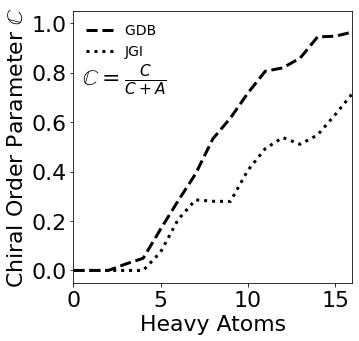

In [21]:
plt.figure(figsize=(5,5))

plt.plot(gdb_cop, linewidth=3, label="GDB ", color="k", linestyle="--")
plt.plot(JGI_cop, linewidth=3, label="JGI", color="k", linestyle=":")

#plt.axvspan(7, 12, alpha=0.5, color='grey', label="Laurent\nCrossover")

legend = plt.legend(frameon=False, prop={"size":14})

plt.xlim(0,16)
plt.ylim(-0.05, 1.05)
plt.xlabel("Heavy Atoms")
plt.ylabel("Chiral Order Parameter $\mathbb{C}$")

plt.annotate(xy=(0.5,0.75), text=r"$\mathbb{C} = \frac{C}{C+A}$", )



## Figure 1

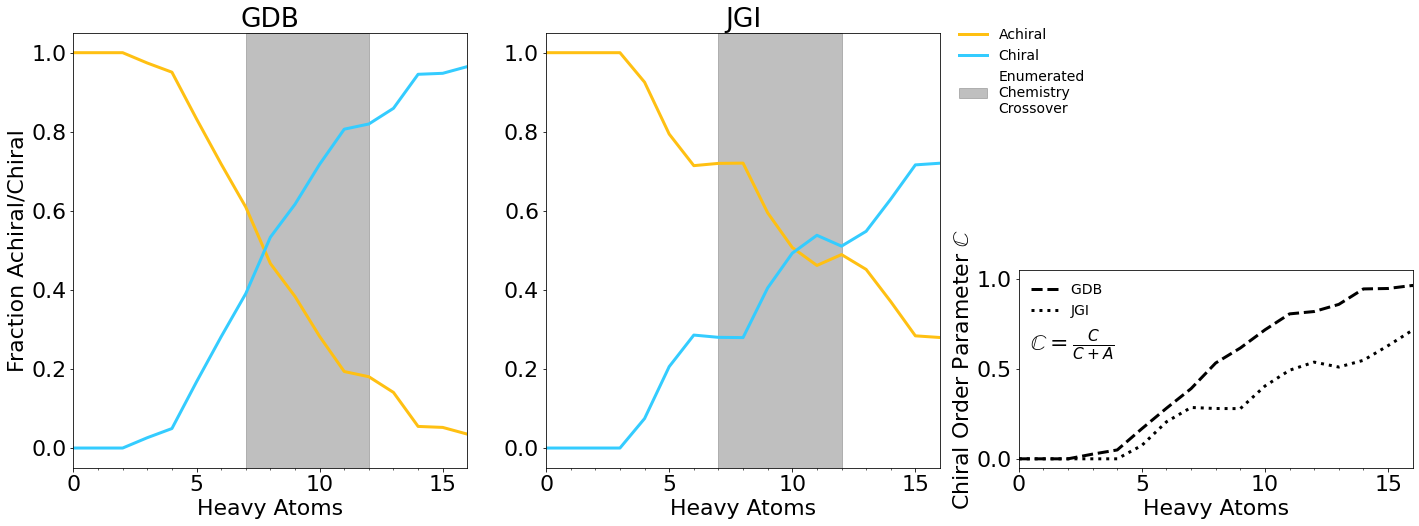

In [26]:
import matplotlib.gridspec as gridspec

plt.rcParams['figure.constrained_layout.use'] = False

plt.figure(figsize=(24,8))

gs = gridspec.GridSpec(2,6)

ax1 = plt.subplot(gs[:,0:2])

ax1.plot(gdb_df["fraction_achiral"], linewidth=3, label="Achiral", color=achiral_color)
ax1.plot(gdb_df["fraction_chiral"], linewidth=3, label="Chiral", color=chiral_color)

ax1.axvspan(7, 12, alpha=0.5, color='grey', label="Laurent\nCrossover")

#ax1.legend(prop={"size":14})

ax1.set_xlim(0,16)
ax1.set_ylim(-0.05, 1.05)
ax1.set_xticks(list(np.arange(0,16)), minor=True)
ax1.set_xlabel("Heavy Atoms")
ax1.set_ylabel("Fraction Achiral/Chiral")

ax1.set_title("GDB")


ax2 = plt.subplot(gs[:,2:4])

ax2.plot(all_achiral_fraction, linewidth=3, label="Achiral", color=achiral_color)
ax2.plot(all_chiral_fraction, linewidth=3, label="Chiral", color=chiral_color)

ax2.axvspan(7, 12, alpha=0.5, color='grey', label="Enumerated\nChemistry\nCrossover")

ax2.legend(prop={"size":14}, bbox_to_anchor=(1.4, 0.78), frameon=False)

ax2.set_xlim(0,16)
ax2.set_ylim(-0.05, 1.05)
ax2.set_xticks(list(np.arange(0,16)), minor=True)
ax2.set_xlabel("Heavy Atoms")
#ax2.set_ylabel("Fraction Achiral/Chiral")
ax2.set_title("JGI")

ax3 = plt.subplot(gs[1,4:])
ax3.plot(gdb_cop, linewidth=3, label="GDB ", color="k", linestyle="--")
ax3.plot(JGI_cop, linewidth=3, label="JGI", color="k", linestyle=":")

ax3.legend(frameon=False, prop={"size":14})
ax3.set_xlim(0,16)
ax3.set_ylim(-0.05, 1.05)
ax3.set_xticks(list(np.arange(0,16)), minor=True)
ax3.set_xlabel("Heavy Atoms")
ax3.set_ylabel("Chiral Order Parameter $\mathbb{C}$")

ax3.annotate(xy=(0.45,0.6), text=r"$\mathbb{C} = \frac{C}{C+A}$", )

plt.subplots_adjust(wspace=0.5)

plt.savefig("fig1.svg")